# So sánh các mốc 25%, 50% và 75% học kỳ

**Ngày tổng hợp: 14/09/2026.**

Notebook này trình bày lại thí nghiệm đã chạy ở ba mốc tiến trình:

- **25%:** cảnh báo sớm, nhưng dữ liệu hành vi còn ít.
- **50%:** cân bằng giữa thời gian can thiệp và lượng thông tin.
- **75%:** dự đoán dễ hơn vì có nhiều dữ liệu, nhưng thời gian hỗ trợ còn ít.

Thí nghiệm gốc dùng HistGradientBoosting baseline, threshold 0.5 và chia theo `id_student`. Bảng lịch sử đã đánh giá trực tiếp trên test khi so sánh mốc, vì vậy chỉ dùng như **pilot mô tả**, không dùng để chọn cấu hình cuối cùng.

## 1. Đọc bảng kết quả

Các chỉ số gồm Accuracy, Recall risk, Weighted F1 và AP risk. Mỗi mốc có số dòng khác nhau vì những enrollment không còn hợp lệ tại cutoff tương ứng có thể bị loại.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd()
if not (ROOT / 'ket_qua').exists() and (ROOT.parent / 'ket_qua').exists():
    ROOT = ROOT.parent

RESULT_PATH = ROOT / 'ket_qua' / 'so_sanh_cac_moc_hoc_ky.csv'
FIGURE_PATH = ROOT / 'hinh' / 'so_sanh_cac_moc_hoc_ky.png'

ket_qua = pd.read_csv(RESULT_PATH)
ket_qua['moc_hoc_ky'] = ket_qua['cutoff_fraction'].map({0.25: '25% - đầu kỳ', 0.50: '50% - giữa kỳ', 0.75: '75% - cuối kỳ'})
display(ket_qua[['moc_hoc_ky', 'rows', 'accuracy', 'recall_risk', 'weighted_f1', 'average_precision_risk', 'alerts', 'n']].round(4))

,moc_hoc_ky,rows,accuracy,recall_risk,weighted_f1,average_precision_risk,alerts,n
0,25% - đầu kỳ,26239,0.7538,0.5766,0.7461,0.7908,1215,3920
1,50% - giữa kỳ,24599,0.8225,0.6443,0.8164,0.8595,1055,3696
2,75% - cuối kỳ,23159,0.8635,0.6749,0.8579,0.8880,886,3464


## 2. Vẽ xu hướng theo tiến trình

Đường đi lên cho thấy dự đoán thường tốt hơn khi có thêm dữ liệu. Tuy nhiên, mốc muộn hơn không nhất thiết tốt hơn về mặt can thiệp thực tế.

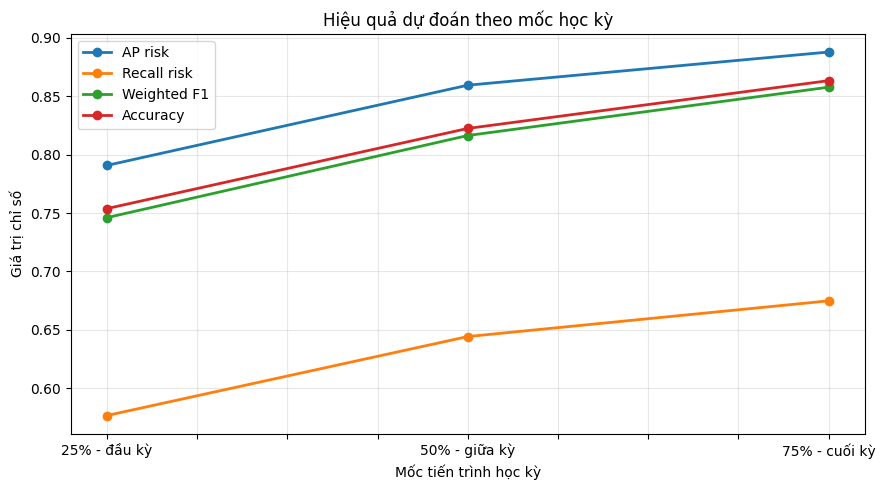

In [2]:
fig, ax = plt.subplots(figsize=(9, 5))
plot_frame = ket_qua.set_index('moc_hoc_ky')[['average_precision_risk', 'recall_risk', 'weighted_f1', 'accuracy']]
plot_frame.plot(marker='o', linewidth=2, ax=ax)
ax.set_xlabel('Mốc tiến trình học kỳ')
ax.set_ylabel('Giá trị chỉ số')
ax.set_title('Hiệu quả dự đoán theo mốc học kỳ')
ax.grid(True, alpha=0.3)
ax.legend(['AP risk', 'Recall risk', 'Weighted F1', 'Accuracy'])
fig.tight_layout()
fig.savefig(FIGURE_PATH, dpi=160)
plt.show()

## 3. Kết quả dễ hiểu

| Mốc | AP risk | Recall risk | Accuracy | Ý nghĩa |
|---|---:|---:|---:|---|
| 25% | 0.7908 | 0.5766 | 0.7538 | Cảnh báo sớm nhất nhưng thiếu dữ liệu nên chất lượng thấp hơn. |
| 50% | 0.8595 | 0.6443 | 0.8225 | Điểm cân bằng hợp lý giữa khả năng dự đoán và thời gian hỗ trợ. |
| 75% | 0.8880 | 0.6749 | 0.8635 | Chất lượng tốt nhất trong pilot nhưng có thể quá muộn để can thiệp. |

### Kết luận

Mốc 75% có chỉ số cao nhất không có nghĩa là mốc nên triển khai. Đề tài hiện dùng 50% làm mốc chính vì vẫn còn thời gian hỗ trợ và chất lượng đã tăng rõ so với 25%.

Để kết luận chặt chẽ hơn, lần nghiên cứu tiếp theo phải chọn mốc bằng train/validation và chỉ mở test sau khi đã khóa mốc, model, feature và threshold.